# 2.2.- Regresión Polinómica OLS

La **regresión polinómica** es una técnica que extiende la regresión lineal al permitir que el modelo se ajuste a relaciones no lineales entre las variables independientes y la variable dependiente.

### Idea principal:
- En regresión lineal simple, el modelo es:
  
  $$
  \hat{y} = \beta_0 + \beta_1 x
  $$

- En regresión polinómica de grado $d$, se incluyen potencias de $x$:

  $$
  \hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \cdots + \beta_d x^d
  $$

### Ventajas:
- Permite capturar relaciones curvas o más complejas.
- Se puede usar con una sola variable (regresión polinómica simple) o con varias (regresión polinómica múltiple).

### Inconvenientes:
- Un grado muy alto del polinomio puede producir **sobreajuste**: el modelo se ajusta demasiado al ruido de los datos en lugar de a la tendencia general.
- A mayor grado, mayor complejidad y peor interpretabilidad de los coeficientes.

---

En este notebook usaremos los datos del **conjunto 2 de Anscombe**.  
Este conjunto de datos muestra una relación **claramente no lineal** entre `x` e `y`.  
Veremos cómo una regresión lineal simple no logra capturar la curva y cómo la regresión polinómica mejora el ajuste.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [2]:
# Cargar dataset de Anscombe quintet
url = 'https://raw.githubusercontent.com/Carl-McBride-Ellis/datasets_public/refs/heads/main/Anscombe_quintet_data.csv'
df = pd.read_csv(url).sort_values(by='x1235', ascending=True)

# Seleccionamos el set 2 (que tiene una relación más curva)
df["x"] = df["x1235"]
df["y"] = df["y2"]

df.head()

,x1235,y1,y2,y3,y5,x4,y4,x,y
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,3.10
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,4.74
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,6.13
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,7.26
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,8.14


## Regresión lineal simple en Anscombe (set 2)

Ajustamos una recta de regresión lineal a los datos del **set 2 de Anscombe**.  
Como veremos, la línea recta no es capaz de capturar adecuadamente la relación curva entre `x` e `y`.

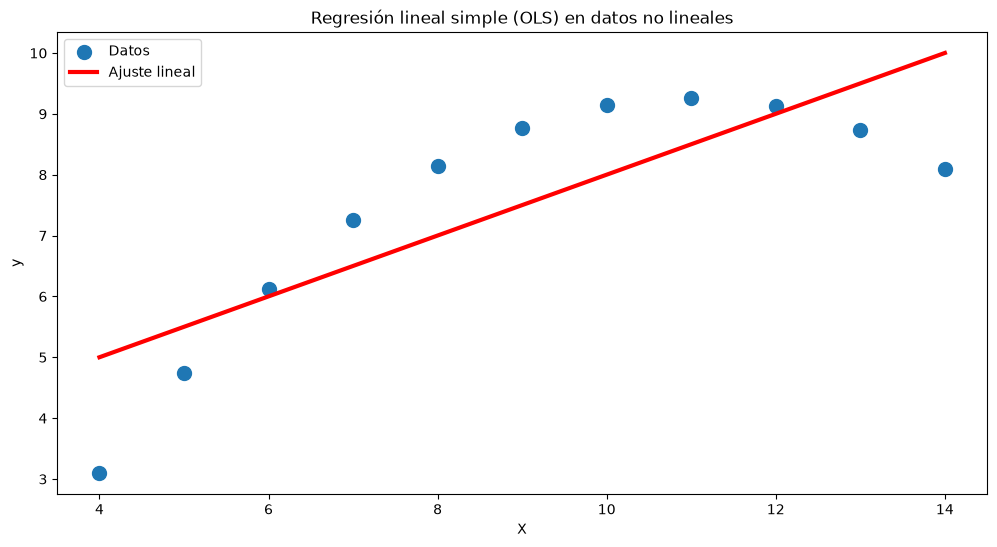

In [3]:
# Definir variables
X = sm.add_constant(df["x"])  # añade la constante (β0)
y = df["y"]

# Ajustar el modelo lineal simple
modelo_lineal = LinearRegression().fit(X, y)

# Predicciones
df["y_pred"] = modelo_lineal.predict(X)

# Visualización en formato estándar
fig = plt.figure(figsize=(12, 6))

# Puntos de datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Recta ajustada
plt.plot(df["x"], df["y_pred"], color="red", lw=3, label="Ajuste lineal")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión lineal simple (OLS) en datos no lineales")
plt.legend()
plt.show()

## Regresión polinómica de grado 2

La regresión polinómica consiste en añadir potencias de la variable `x` como nuevas características.

Para grado 2, el modelo es:

$$
\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2
$$

- La variable $x^2$ permite capturar relaciones cuadráticas (curvas en forma de parábola).
- Seguimos usando una regresión lineal, pero **aplicada a las nuevas variables**: $x$ y $x^2$.
- Esto hace que el modelo gane flexibilidad y se ajuste mejor a datos no lineales.

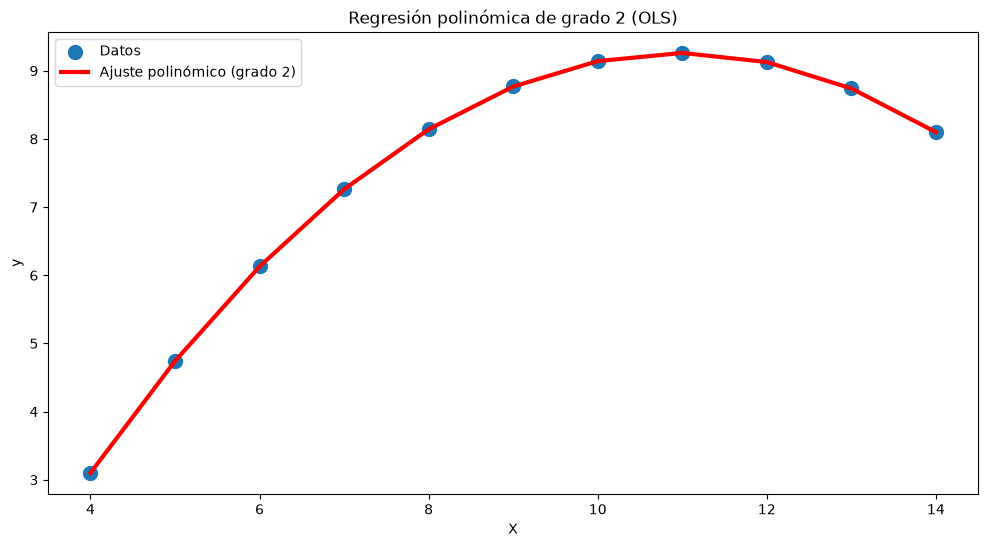

Intercepto (beta_0): -5.9957342657342885
Pendiente (beta_1): 2.7808391608391654
Coeficiente cuadrático (beta_2): -0.1267132867132869


In [4]:
# Generar las nuevas características polinómicas (x y x^2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[["x"]])  # crea columnas: [x, x^2]

# Ajuste del modelo lineal sobre estas nuevas features
modelo_poly2 = LinearRegression().fit(X_poly, df["y"])

# Predicciones
df["y_pred_poly2"] = modelo_poly2.predict(X_poly)

# Visualización
fig = plt.figure(figsize=(12, 6))

# Puntos de datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Curva ajustada (ordenada por x para que la curva salga suave)
plt.plot(df["x"], df["y_pred_poly2"], color="red", lw=3, label="Ajuste polinómico (grado 2)")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión polinómica de grado 2 (OLS)")
plt.legend()
plt.show()

# Coeficientes
print("Intercepto (beta_0):", modelo_poly2.intercept_)
print("Pendiente (beta_1):", modelo_poly2.coef_[0])
print("Coeficiente cuadrático (beta_2):", modelo_poly2.coef_[1])

## Interpretación de los coeficientes en regresión polinómica

El modelo ajustado de grado 2 es:

$$
\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2
$$

- **Intercepto ($\beta_0$):**  
  Valor de $\hat{y}$ cuando $x = 0$. Representa el punto de corte con el eje $y$.

- **Pendiente ($\beta_1$):**  
  Representa el cambio lineal de $y$ por cada unidad que aumenta $x$.  
  En este caso, no describe toda la tendencia, ya que existe curvatura.

- **Coeficiente cuadrático ($\beta_2$):**  
  Captura la **curvatura** de la relación.  
  - Si $\beta_2 > 0$, la curva se abre hacia arriba (forma de U).  
  - Si $\beta_2 < 0$, la curva se abre hacia abajo (forma de ∩).  